In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
figsave='figures_draft'

### GSVA heatmap

In [3]:
import gseapy as gp

In [5]:
import pickle 
with open('../DEGs/pyDESeq2/iA_DEGs_all.pkl','rb') as f:
    iA_DEGs = pickle.load(f)

In [6]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_sig_nDEGs.csv"), index_col=0)

iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index
common_genes = set(iA_top_genes) & set (iN_top_genes)
common_genes

{'CCT3',
 'CHMP7',
 'DCAF7',
 'FDFT1',
 'HDAC2',
 'LSM4',
 'MRPL39',
 'RPA3',
 'RPL10',
 'RPL30',
 'SOD1',
 'SOD2',
 'SYVN1',
 'UBA1',
 'WDR12'}

In [7]:
programs = pd.read_excel('/lustre/scratch126/cellgen/lotfollahi/so21/patientAtlases/Meir2025Biorxiv/media-3.xlsx', sheet_name='DEGs')
print (programs.shape)
programs.head(5)

ExN = [i for i in programs.program.unique() if i.startswith('EXC L2-3')]
ExN = programs[programs.program.isin(ExN)]
ExN = ExN.groupby('program')['gene'].apply(list).to_dict()

Ast = [i for i in programs.program.unique() if i.startswith('AST')]
Ast = programs[programs.program.isin(Ast)]
Ast = Ast.groupby('program')['gene'].apply(list).to_dict()

(36836, 9)


In [8]:
genesets = Ast

In [9]:
def run_gsea_for_common(de_dict, cell_type, selected_perturbations, genesets):
    out = []

    for pert in selected_perturbations:
        if pert not in de_dict:
            continue

        de = de_dict[pert]

        rnk = (
            de[["variable", "stat"]]
            .rename(columns={"variable": "gene", "stat": "score"})
            .dropna()
            .drop_duplicates("gene")
            .sort_values("score", ascending=False)
        )

        pre = gp.prerank(
            rnk=rnk,
            gene_sets=genesets,
            permutation_num=1000,
            min_size=5,
            max_size=1000,
            outdir=None,
            seed=6,
            verbose=False,
        )

        tmp = pre.res2d.copy()
        tmp["perturbation"] = pert
        tmp["cell_type"] = cell_type
        out.append(tmp)

    return pd.concat(out, ignore_index=True)

### combined

In [10]:
iA_gsea = run_gsea_for_common(de_dict = iA_DEGs, 
                              cell_type="iAstrocytes", 
                              selected_perturbations=list(iA_nDEGs_df.index),
                              genesets=genesets)

2026-07-28 15:15:27,302 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-07-28 15:15:32,328 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-07-28 15:15:37,120 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-07-28 15:15:41,685 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-07-28 15:15:45,120 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-07-28 15:15:48,825 [WARNING] Duplicated values found in preranked stats: 1.40% of genes
The order of those genes will be

In [10]:
iA_gsea.to_csv('temp_iA_gsea_NMF.csv')

NameError: name 'iA_gsea' is not defined

In [10]:
sns.set_style('ticks')

In [11]:
iA_gsea = pd.read_csv('temp_iA_gsea_NMF.csv', index_col=0)
iA_gsea.head(2)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,perturbation,cell_type
0,prerank,AST.p6,0.353911,1.334919,0.003881,0.022437,0.024000,131/362,20.67%,TRPM3;RPS6KA3;VEGFA;ADRA1A;ARNTL;SSBP2;JAKMIP3...,AARD,iAstrocytes
1,prerank,AST.p10,-0.309744,-1.291040,0.004651,0.020228,0.019851,115/382,15.09%,GPHN;TCF4;PELI2;MKLN1;XPO1;KIAA1958;TANK;PCGF5...,AARD,iAstrocytes


In [12]:
# signatures significant in at least x perturbation

min_perts = 3

sig_terms = (
    iA_gsea.loc[iA_gsea["FDR q-val"] < 0.05]
    .groupby("Term")["perturbation"]
    .nunique()
)

sig_terms = sig_terms[sig_terms >= min_perts].index

# keep only those signatures
plot_df = iA_gsea[iA_gsea["Term"].isin(sig_terms)]

# NES matrix
heatmap_df = plot_df.pivot(
    index="Term",
    columns="perturbation",
    values="NES"
)

### GSVA heatmap with significant terms

In [13]:
keep_terms = list(sig_terms)
signatures = genesets
signatures = {k:v for k,v in signatures.items() if k in keep_terms}

In [14]:
def get_ot_scores(disease_id):
    query = """
    query DiseaseAssociations($efoId: String!) {
      disease(efoId: $efoId) {
        associatedTargets(page: {index: 0, size: 1000}) {
          rows {
            target {
              approvedSymbol
            }
            score
          }
        }
      }
    }
    """

    r = requests.post(
        "https://api.platform.opentargets.org/api/v4/graphql",
        json={
            "query": query,
            "variables": {"efoId": disease_id}
        }
    )

    rows = r.json()["data"]["disease"]["associatedTargets"]["rows"]

    df = pd.DataFrame({
        "gene": [x["target"]["approvedSymbol"] for x in rows],
        "score": [x["score"] for x in rows]
    })

    return (
        df
        .dropna(subset=["gene"])
        .groupby("gene", as_index=False)["score"]
        .max()
    )

In [15]:
psadata = sc.read('../adatas/pseudobulk_iAstrocytes.h5ad')

print (psadata.X.max())
sc.pp.normalize_total(psadata, target_sum=1e6, inplace=True)
print (psadata.X.max())
sc.pp.log1p(psadata)
print (psadata.X.max())

exp_df = psadata.to_df().T
exp_df.head(2)

psadata

1429896.0
16801.57981298146
9.72928771389869


AnnData object with n_obs × n_vars = 490 × 36601
    obs: 'sequencing_batch', 'target_gene', 'psbulk_cells', 'psbulk_counts'
    uns: 'log1p'
    layers: 'psbulk_props'

In [16]:
import gseapy as gp

In [17]:
gsva_res = gp.gsva(
    data=exp_df,              # genes × samples (DataFrame)
    gene_sets=signatures, # dict: set_name -> list of genes
    method="gsva",                 # "gsva" (default), or "ssgsea"
    kcdf="Gaussian",               # typical for log-expression; use "Poisson" for counts
    min_sz=5,
    max_sz=2000,
    mx_diff=True,                  # standard GSVA behavior
    verbose=True
)

# gseapy returns a result object; the scores are typically in .res2d
scores = gsva_res.res2d  # usually: pathways × samples

gsva_wide = (
    scores
    .pivot(index="Name", columns="Term", values="ES")
    .sort_index()
)

gsva_by_ko = (
    gsva_wide
    .groupby(psadata.obs["target_gene"])
    .mean()
)

### z score
gsva_z = (gsva_by_ko - gsva_by_ko.mean()) / gsva_by_ko.std()
gsva_z = gsva_z.astype('float')

2026-10-08 18:42:39,446 [INFO] Parsing data files for GSVA.............................
2026-10-08 18:42:39,740 [INFO] Estimating ECDFs with Gaussian kernels.
2026-10-08 18:42:39,861 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=15
2026-10-08 18:42:39,865 [INFO] 0008 gene_sets used for further statistical testing.....
2026-10-08 18:42:39,866 [INFO] Start to run GSVA...Might take a while................
2026-10-08 18:43:18,288 [INFO] Done


In [18]:
import requests
import seaborn as sns
sns.set_style('ticks')

diseases = {
    "AD": "MONDO_0004975",
    "PD": "MONDO_0005180",
    "ALS": "MONDO_0004976",
}

ann = pd.DataFrame(index=gsva_z.index)

for disease, disease_id in diseases.items():
    tmp = get_ot_scores(disease_id)
    ann[disease] = (
        tmp
        .set_index("gene")
        .reindex(gsva_z.index)["score"]
        .fillna(0)
    )
    
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize

cmap = sns.color_palette("Reds", as_cmap=True)

row_colors = pd.DataFrame(index=gsva_z.index)

for disease in ann.columns:
    row_colors[disease] = [
        mcolors.to_hex(c)
        for c in cmap(Normalize(0, 1)(ann[disease]))
    ]
    
url = "https://static-content.springer.com/esm/art%3A10.1038%2Fs41588-020-00776-w/MediaObjects/41588_2020_776_MOESM3_ESM.xlsx"

gwas = pd.read_excel(
    url,
    sheet_name="13-gene evidence rankings"
)

gwas.head(3)

# collapse GWAS evidence rankings to one score per gene
gwas_gene = (
    gwas[["symbol", "total score"]]
    .rename(columns={
        "symbol": "gene",
        "total score": "gwas_total_score"
    })
    .dropna(subset=["gene", "gwas_total_score"])
    .groupby("gene", as_index=False)["gwas_total_score"]
    .max()
)

# align to GSVA genes
ann["GWAS_total_score"] = (
    gwas_gene
    .set_index("gene")
    .reindex(gsva_z.index)["gwas_total_score"]
    .fillna(0)
)

# add as extra row annotation
gwas_norm = Normalize(
    vmin=0,
    vmax=ann["GWAS_total_score"].quantile(0.99)
)

row_colors["AD GWAS"] = [
    mcolors.to_hex(c)
    for c in cmap(gwas_norm(ann["GWAS_total_score"]))
]

import pickle
#with open("../DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
#    iA_DEGs_sig_dict = pickle.load(f)

#with open("../DEGs/pyDESeq2/iN_DEGs_sig.pkl", "rb") as f:
#    iN_DEGs_sig_dict = pickle.load(f)
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

# align nDEGs to GSVA rows
ann["iA_log10_nDEGs"] = (
    np.log10(iA_nDEGs_df["nDEGs"] + 1)
    .reindex(gsva_z.index)
    .fillna(0)
)

ann["iN_log10_nDEGs"] = (
    np.log10(iN_nDEGs_df["nDEGs"] + 1)
    .reindex(gsva_z.index)
    .fillna(0)
)

deg_cmap = sns.color_palette("Blues", as_cmap=True)

deg_max = max(
    ann["iA_log10_nDEGs"].max(),
    ann["iN_log10_nDEGs"].max()
)

deg_norm = Normalize(0.59, deg_max)

row_colors["iA log10 nDEGs"] = [
    mcolors.to_hex(c)
    for c in deg_cmap(deg_norm(ann["iA_log10_nDEGs"]))
]

row_colors["iN log10 nDEGs"] = [
    mcolors.to_hex(c)
    for c in deg_cmap(deg_norm(ann["iN_log10_nDEGs"]))
]

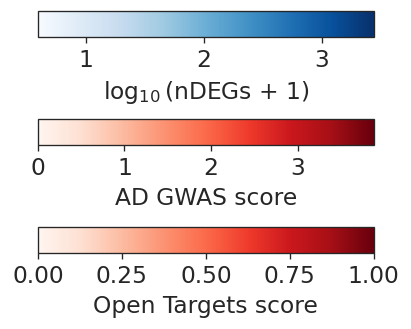

In [19]:
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# Exact mappings
disease_sm = ScalarMappable(
    norm=Normalize(0, 1),
    cmap=cmap
)

gwas_sm = ScalarMappable(
    norm=gwas_norm,
    cmap=cmap
)

deg_sm = ScalarMappable(
    norm=deg_norm,
    cmap=deg_cmap
)

fig = plt.figure(figsize=(4, 3))

# 1. DEGs
cax1 = fig.add_axes([0.15, 0.75, 0.7, 0.07])
cb1 = fig.colorbar(deg_sm, cax=cax1, orientation="horizontal")
cb1.set_label(r"$\log_{10}$(nDEGs + 1)")

# 2. AD GWAS
cax2 = fig.add_axes([0.15, 0.45, 0.7, 0.07])
cb2 = fig.colorbar(gwas_sm, cax=cax2, orientation="horizontal")
cb2.set_label("AD GWAS score")

# 3. Open Targets
cax3 = fig.add_axes([0.15, 0.15, 0.7, 0.07])
cb3 = fig.colorbar(disease_sm, cax=cax3, orientation="horizontal")
cb3.set_label("Open Targets score")

plt.savefig(
    "figures/heatmap_annotation_colorbars_iA_NMF.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()

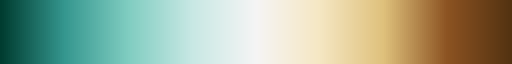

In [20]:
from matplotlib.colors import LinearSegmentedColormap

palette = [
    "#533211",
    "#8c5322",
    "#dfc17c",
    "#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    #"#03675e",
    "#003c30"
]
palette= palette[::-1]

cmap = LinearSegmentedColormap.from_list("brown_teal", palette)
cmap

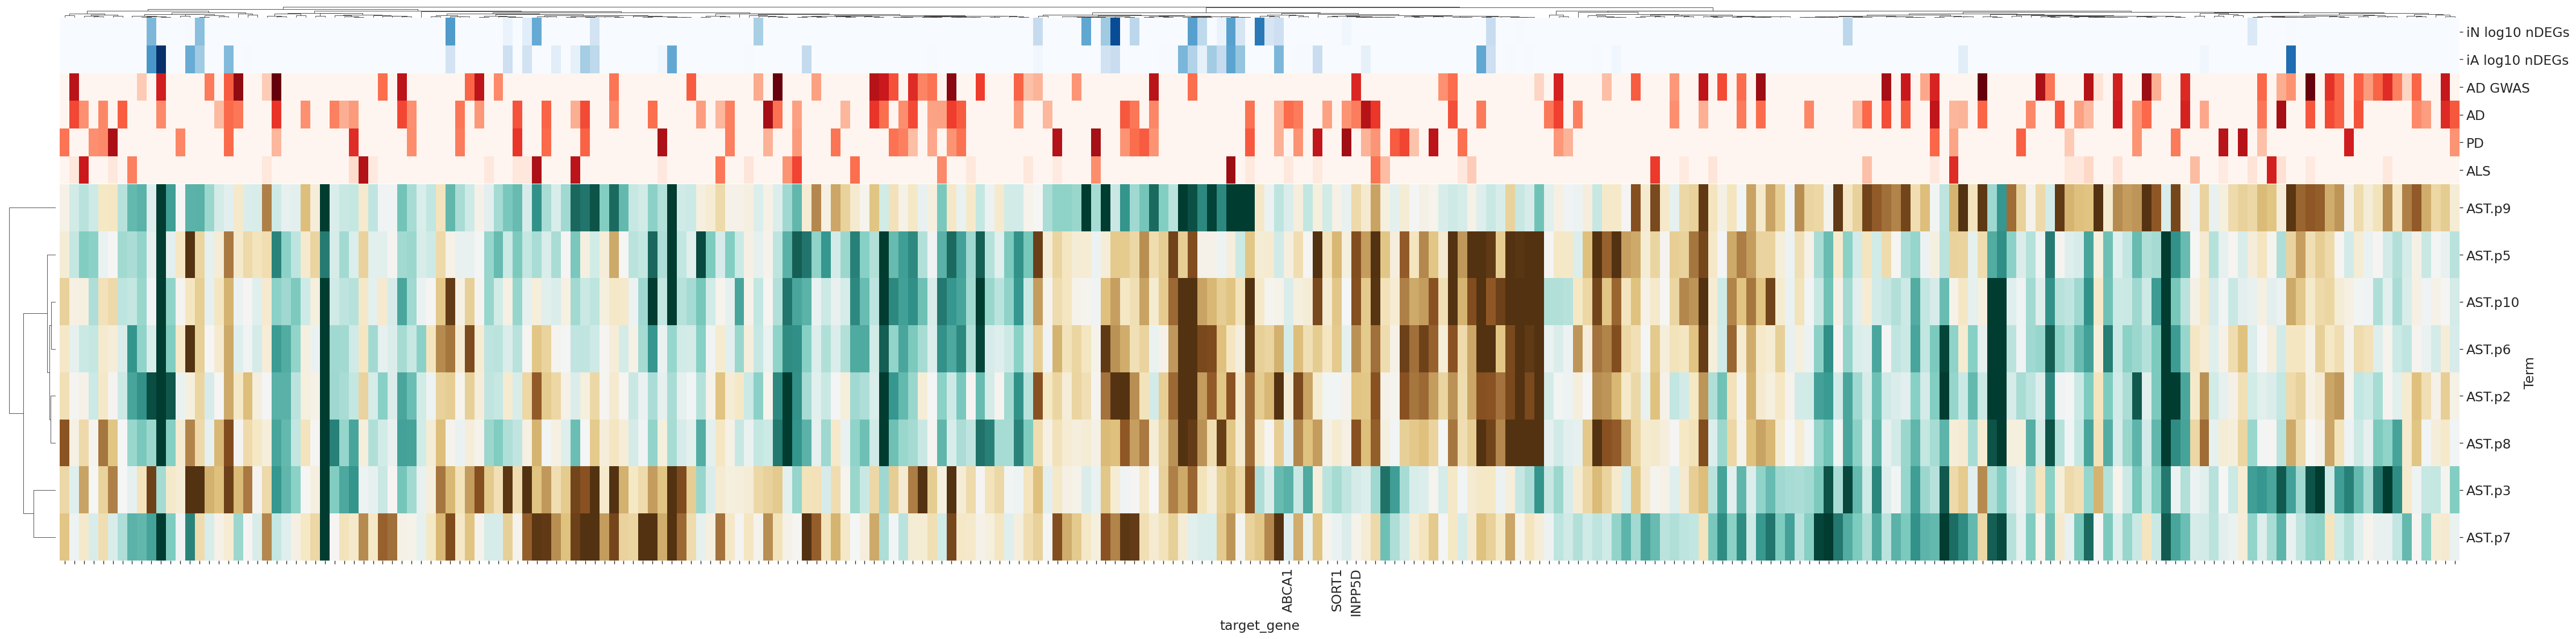

In [21]:
import re

# Genes to label = union of top iNeuron and iAstrocyte perturbations
#label_genes = set(iN_top_genes) | set(iA_top_genes)

label_genes = ['ABCA1', 'INPP5D', 'SORT1']


def clean_term(term):
    # Remove GO ID brackets, e.g.
    # "lysosome organization (GO:0007040)" -> "lysosome organization"
    term = re.sub(r"\s*\(GO:\d+\)\s*", "", term)

    # Clean Hallmark names
    if term.startswith("HALLMARK_"):
        term = term.replace("HALLMARK_", "Hallmark ").replace("_", " ").title()

    return term

g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,
    row_cluster=True,
    col_cluster=True,
    col_colors=row_colors[['iN log10 nDEGs','iA log10 nDEGs','AD GWAS','AD', 'PD', 'ALS']],
    colors_ratio=0.05,
    figsize=(38, 10),
    xticklabels=True,
    yticklabels=True,
    dendrogram_ratio=(0.02, 0.02),  # hide dendrograms but keep clustering
    metric="correlation",
    method="average",
    cbar_pos=None
)

# Only label selected perturbation genes on columns
g.ax_heatmap.set_xticklabels([
    x.get_text() if x.get_text() in label_genes else ""
    for x in g.ax_heatmap.get_xticklabels()
], rotation=90)

# Clean ALL pathway/signature labels on rows
g.ax_heatmap.set_yticklabels([
    clean_term(x.get_text())
    for x in g.ax_heatmap.get_yticklabels()
])

plt.savefig('figures/heatmap_GSVA_GSEAfiltered_NMF_iA.pdf')

# Get row/column order after clustering
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

# Reorder the original data
gsva_z_clustered = gsva_z.T.iloc[row_order, col_order]

# Save
gsva_z_clustered.to_csv("figures/heatmap_GSVA_GSEAfiltered_NMF_iA_clustered.csv")

In [21]:
from scipy.cluster.hierarchy import fcluster

# linkage for perturbation genes
Z_genes = g.dendrogram_col.linkage

# cut dendrogram
t = 0.77  # adjust after looking at dendrogram

gene_clusters = pd.Series(
    fcluster(
        Z_genes,
        t=t,
        criterion="distance"
    ),
    index=gsva_z.T.columns,
    name="cluster"
)

gene_clusters.value_counts().sort_index()

cluster
1    21
2    16
3    64
4    53
5     3
6    92
Name: count, dtype: int64

In [22]:
for cluster in sorted(gene_clusters.unique()):
    genes = gene_clusters[gene_clusters == cluster].index.tolist()
    print(f"\nCluster {cluster} (n={len(genes)}):")
    print(genes)

supp_table = (
    gene_clusters
    .rename("Cluster")
    .rename_axis("Gene")
    .reset_index()
    .sort_values(["Cluster", "Gene"])
)

supp_table

supp_table.to_csv('cluster_heatmap_iAstrocytes_NMF.csv')


Cluster 1 (n=21):
['ANKH', 'ATG14', 'BAG3', 'CCDC6', 'CELSR1', 'GCH1', 'GPX3', 'GRB10', 'GUK1', 'HDAC2', 'KAT8', 'PRKN', 'QPCT', 'SHARPIN', 'SIGMAR1', 'SYNJ1', 'SYVN1', 'TMEM121', 'TREM2', 'TSPAN14', 'USP6']

Cluster 2 (n=16):
['ANK3', 'ANXA6', 'APH1B', 'B3GNT4', 'BLNK', 'CR1', 'CTSL', 'ELAVL2', 'INT', 'ITGAX', 'MAF', 'MAPK9', 'MAPT', 'NIPSNAP3B', 'TBK1', 'WDR81']

Cluster 3 (n=64):
['ACE', 'ACTR2', 'ADAM17', 'ALKBH5', 'AP4E1', 'ARHGAP45', 'ATP6V1A', 'C1orf159', 'CASS4', 'CCT3', 'CD33', 'COG3', 'COQ2', 'CTSB', 'DRG2', 'EED', 'EIF4A3', 'FAM171A2', 'FCER1G', 'FERMT2', 'HMGCR', 'ICA1', 'ICA1L', 'IDUA', 'ITPK1', 'JAM2', 'LILRB5', 'LRP1', 'MAF1', 'MOBP', 'NCK2', 'NEK1', 'PDIA3', 'PINK1', 'PRKD3', 'PSAP', 'PSEN1', 'PTPRN2', 'RASA1', 'RBCK1', 'REXO1', 'RIN3', 'RORA', 'RPL30', 'SCIN', 'SEC61G', 'SIPA1L2', 'SOD2', 'TARDBP', 'TEDC1', 'THSD7A', 'TMEM106B', 'TMEM163', 'TNFRSF21', 'TNIP1', 'TRAPPC5', 'TUBB4A', 'UNC13A', 'USP8', 'VCP', 'WDR12', 'WDR45B', 'ZCWPW1', 'ZYX']

Cluster 4 (n=53):
['ABCA1'

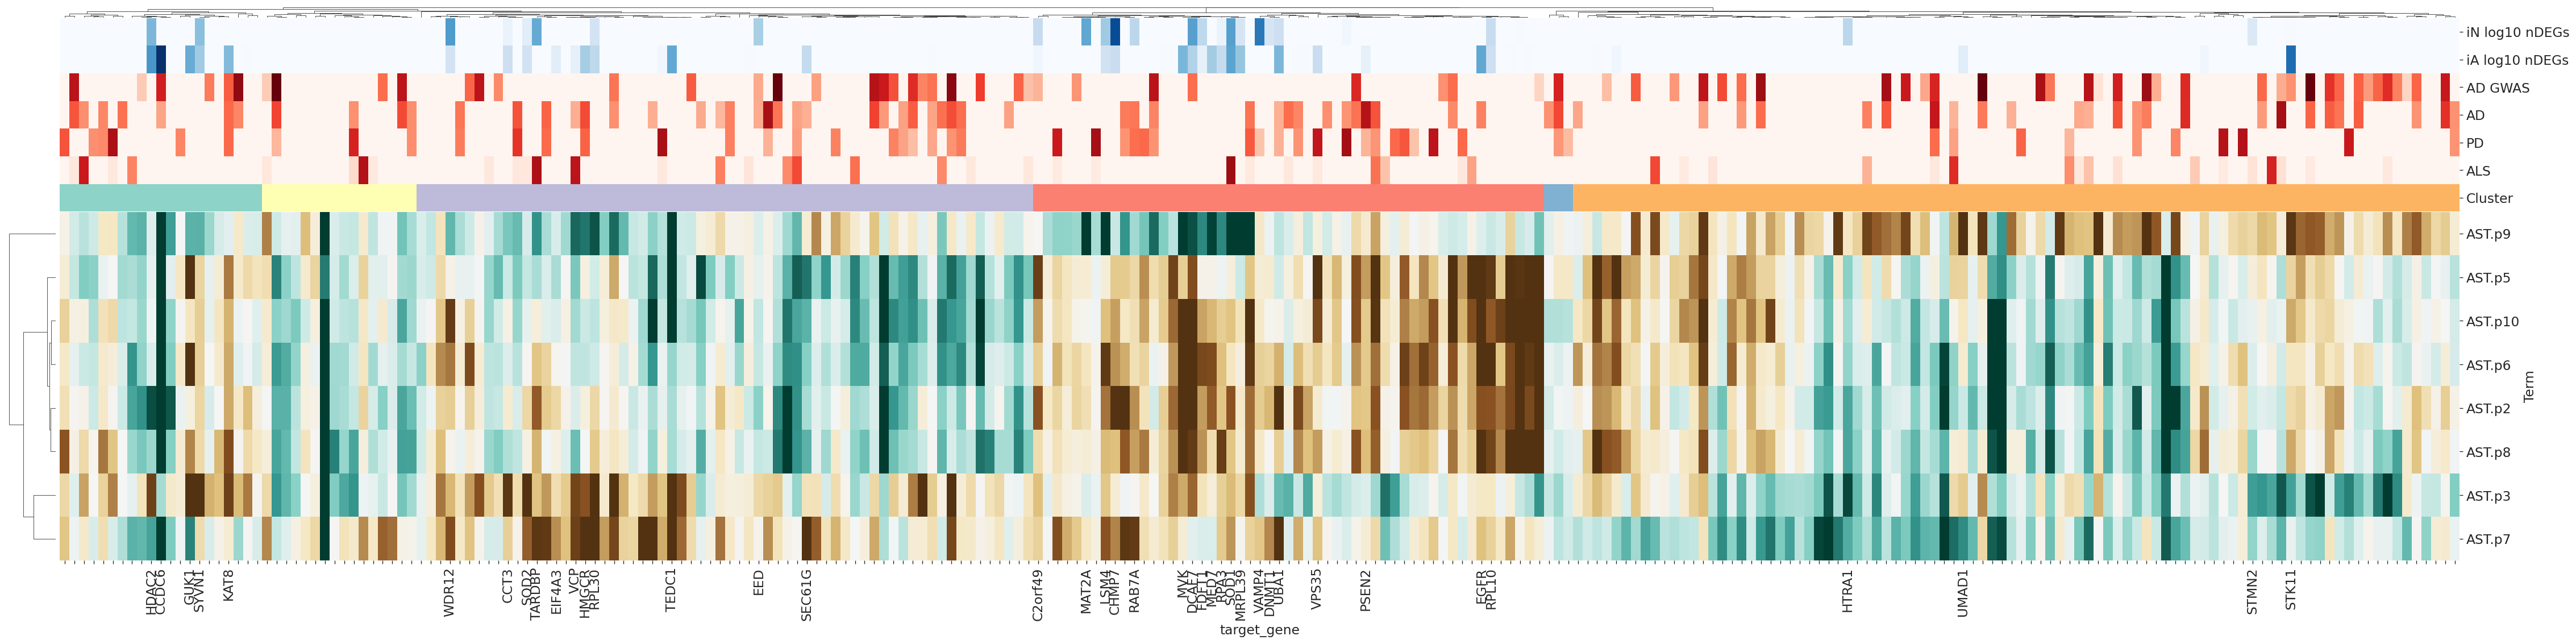

In [23]:
import re

# Genes to label = union of top iNeuron and iAstrocyte perturbations
label_genes = set(iN_top_genes) | set(iA_top_genes)


def clean_term(term):
    # Remove GO ID brackets
    term = re.sub(r"\s*\(GO:\d+\)\s*", "", term)

    # Clean Hallmark names
    if term.startswith("HALLMARK_"):
        term = term.replace("HALLMARK_", "Hallmark ").replace("_", " ").title()

    return term


# --------------------------------------------------
# Gene cluster annotation
# --------------------------------------------------

palette_clusters = [
    "#8dd3c7",
    "#ffffb3",
    "#bebada",
    "#fb8072",
    "#80b1d3",
    "#fdb462",
    "#b3de69",
    "#fccde5"
]

uniq = sorted(gene_clusters.unique())
cluster_lut = dict(zip(uniq, palette_clusters))

cluster_colors = gene_clusters.map(cluster_lut)


# --------------------------------------------------
# Combine annotations
# --------------------------------------------------

annotation_colors = row_colors[
    [
        'iN log10 nDEGs',
        'iA log10 nDEGs',
        'AD GWAS',
        'AD',
        'PD',
        'ALS'
    ]
].copy()

annotation_colors["Cluster"] = cluster_colors


# --------------------------------------------------
# Heatmap
# --------------------------------------------------

g = sns.clustermap(
    gsva_z.T,
    cmap=cmap,
    center=0,
    vmax=2,
    vmin=-2,

    row_cluster=True,
    col_cluster=True,

    # Reuse the linkage used to define the clusters
    col_linkage=Z_genes,

    col_colors=annotation_colors,
    colors_ratio=0.05,
    figsize=(38, 10),
    xticklabels=True,
    yticklabels=True,
    dendrogram_ratio=(0.02, 0.02),  # hide dendrograms but keep clustering
    metric="correlation",
    method="average",
    cbar_pos=None
)


# --------------------------------------------------
# Only label selected perturbation genes
# --------------------------------------------------

g.ax_heatmap.set_xticklabels([
    x.get_text() if x.get_text() in label_genes else ""
    for x in g.ax_heatmap.get_xticklabels()
], rotation=90)


# --------------------------------------------------
# Clean pathway/signature labels
# --------------------------------------------------

g.ax_heatmap.set_yticklabels([
    clean_term(x.get_text())
    for x in g.ax_heatmap.get_yticklabels()
])


# --------------------------------------------------
# Save
# --------------------------------------------------

plt.savefig(
    'figures/heatmap_GSVA_GSEAfiltered_NMF_iA_clustered.pdf',
    bbox_inches="tight"
)

In [24]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu

results = []

# Combine dendrogram clusters with annotations
cluster_ann = ann.copy()
cluster_ann["Cluster"] = gene_clusters

cluster_ann.head()

for cluster in sorted(cluster_ann["Cluster"].unique()):

    in_cluster = cluster_ann["Cluster"] == cluster

    x = cluster_ann.loc[in_cluster, "AD"].dropna()
    y = cluster_ann.loc[~in_cluster, "AD"].dropna()

    stat, p = mannwhitneyu(
        x,
        y,
        alternative="greater"
    )

    results.append({
        "Cluster": cluster,
        "n_genes": len(x),
        "median_OTAR": x.median(),
        "mean_OTAR": x.mean(),
        "pvalue": p
    })

otar_enrichment = pd.DataFrame(results)

otar_enrichment["padj"] = multipletests(
    otar_enrichment["pvalue"],
    method="fdr_bh"
)[1]

otar_enrichment

,Cluster,n_genes,median_OTAR,mean_OTAR,pvalue,padj
0,1,21,0.000000,0.145821,0.380230,0.760459
1,2,16,0.000000,0.121896,0.623506,0.803189
2,3,64,0.000000,0.161844,0.124630,0.373890
3,4,53,0.000000,0.121188,0.741287,0.803189
4,5,3,0.376013,0.322882,0.068268,0.373890
5,6,92,0.000000,0.125880,0.803189,0.803189


In [25]:
results = []

# Combine dendrogram clusters with annotations
cluster_ann = ann.copy()
cluster_ann["Cluster"] = gene_clusters

cluster_ann.head()

for cluster in sorted(cluster_ann["Cluster"].unique()):

    in_cluster = cluster_ann["Cluster"] == cluster

    x = cluster_ann.loc[in_cluster, "GWAS_total_score"].dropna()
    y = cluster_ann.loc[~in_cluster, "GWAS_total_score"].dropna()

    stat, p = mannwhitneyu(
        x,
        y,
        alternative="greater"
    )

    results.append({
        "Cluster": cluster,
        "n_genes": len(x),
        "median": x.median(),
        "mean": x.mean(),
        "pvalue": p
    })

otar_enrichment = pd.DataFrame(results)

otar_enrichment["padj"] = multipletests(
    otar_enrichment["pvalue"],
    method="fdr_bh"
)[1]

otar_enrichment

,Cluster,n_genes,median,mean,pvalue,padj
0,1,21,0.0,0.673143,0.459638,0.717390
1,2,16,0.0,0.661375,0.597825,0.717390
2,3,64,0.0,0.629531,0.525693,0.717390
3,4,53,0.0,0.268208,0.995620,0.995620
4,5,3,0.0,0.923333,0.378755,0.717390
5,6,92,0.0,0.833772,0.011538,0.069226
